# First Machine Learning Classifier: Predicting Titanic Survival

## The prediction
**Predict whether a passenger survived from their class, sex, age and fare.**

- **Target** (what we predict): `survived` (1 = survived, 0 = did not survive)
- **Features** (the information we give the model): `pclass`, `sex`, `age`, `fare`

Data: the Titanic dataset from seaborn.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

titanic = sns.load_dataset("titanic")
df = titanic[["survived", "pclass", "sex", "age", "fare"]].copy()

print("Before cleaning:", df.shape)
print(df.isna().sum())

Before cleaning: (891, 5)
survived      0
pclass        0
sex           0
age         177
fare          0
dtype: int64


## Preparing the data
- **Missing values:** only `age` has gaps (177 of 891). I drop those rows instead of guessing ages. This leaves 714 passengers, so the model learns from less data, which is a limitation noted at the end.
- **Sex as a number:** models need numbers, not words, so `sex` becomes 1 for female and 0 for male.

In [2]:
df = df.dropna()
df["sex"] = (df["sex"] == "female").astype(int)

print("After cleaning:", df.shape)
df.head()

After cleaning: (714, 5)


,survived,pclass,sex,age,fare
0,0,3,0,22.0,7.2500
1,1,1,1,38.0,71.2833
2,1,3,1,26.0,7.9250
3,1,1,1,35.0,53.1000
4,0,3,0,35.0,8.0500


## Splitting the data

In [3]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="survived")    # the features
y = df["survived"]                 # the target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Training set:", X_train.shape, "| Test set:", X_test.shape)
print("Survival rate in training:", round(y_train.mean(), 3))
print("Survival rate in test:    ", round(y_test.mean(), 3))

Training set: (571, 4) | Test set: (143, 4)
Survival rate in training: 0.406
Survival rate in test:     0.406


## Baseline

In [4]:
most_common = y_train.mode()[0]                       # the most common outcome in training
baseline = (y_test == most_common).mean()             # how often that guess is right on the test set

print("Most common outcome:", most_common, "(0 = did not survive)")
print("Baseline accuracy:", round(baseline, 3))

Most common outcome: 0 (0 = did not survive)
Baseline accuracy: 0.594


## Training and testing the model

In [5]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

model = DecisionTreeClassifier(max_depth=4, random_state=42)
model.fit(X_train, y_train)            # learn from the training data only

pred = model.predict(X_test)           # predict for passengers it has never seen

print("Baseline accuracy:", round(baseline, 3))
print("Model accuracy:   ", round(accuracy_score(y_test, pred), 3))

cm = confusion_matrix(y_test, pred)
pd.DataFrame(cm, index=["Actually died", "Actually survived"],
             columns=["Predicted died", "Predicted survived"])

Baseline accuracy: 0.594
Model accuracy:    0.797


,Predicted died,Predicted survived
Actually died,72,13
Actually survived,16,42


**Result:** The decision tree (max depth 4) scored 0.797 accuracy on the test set, against a baseline of 0.594 for always guessing "did not survive".

**Confusion matrix:** 72 passengers who died were correctly predicted to die, and 42 who survived were correctly predicted to survive. The model wrongly predicted survival for 13 passengers who died, and wrongly predicted death for 16 who survived. It identified about 85% of those who died but only about 72% of those who survived.

## Depth and overfitting

 depth  train  test
     1  0.779 0.783
     2  0.795 0.776
     3  0.818 0.811
     4  0.848 0.797
     5  0.865 0.762
     6  0.883 0.783
     7  0.916 0.783
     8  0.925 0.790
     9  0.947 0.769
    10  0.956 0.762
    11  0.965 0.769
    12  0.968 0.776


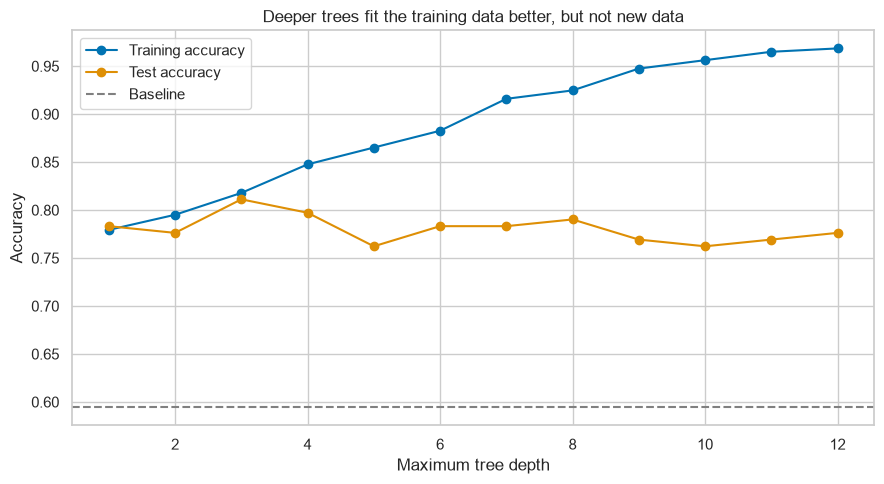

In [6]:
sns.set_theme(style="whitegrid", palette="colorblind")

depths = range(1, 13)
train_acc, test_acc = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    train_acc.append(m.score(X_train, y_train))
    test_acc.append(m.score(X_test, y_test))

results = pd.DataFrame({"depth": list(depths), "train": np.round(train_acc, 3), "test": np.round(test_acc, 3)})
print(results.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(depths, train_acc, marker="o", label="Training accuracy")
ax.plot(depths, test_acc, marker="o", label="Test accuracy")
ax.axhline(baseline, linestyle="--", color="gray", label="Baseline")
ax.set(title="Deeper trees fit the training data better, but not new data",
       xlabel="Maximum tree depth", ylabel="Accuracy")
ax.legend()
plt.tight_layout()
plt.show()

**Overfitting:** Training accuracy rises steadily with tree depth, from 0.779 at depth 1 to 0.968 at depth 12, but test accuracy stays between about 0.76 and 0.81 and does not improve after depth 3. A very deep tree asks so many questions that it memorises the quirks of the individual training passengers, including random noise, instead of learning general patterns. Those quirks do not repeat in new passengers, so accuracy on unseen data stops improving or falls. The gap between training and test accuracy (about 19 points at depth 12) is the sign of overfitting.

## What the model relies on

In [7]:
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importances.round(2))

sex       0.55
pclass    0.24
age       0.14
fare      0.08
dtype: float64


## Summary and limitations
**Result:** The decision tree (max depth 4) reached 0.797 accuracy on the test set, against a baseline of 0.594. Sex (0.55) and ticket class (0.24) were the most important features.

**Limitations:** Dropping rows with a missing age removed about 20% of passengers. The test set has only 143 passengers, so small differences between depths are not meaningful. Choosing a depth by looking at the test set is a mild form of using it to make a choice. The model uses only four features, and feature importance shows association, not cause. See `results_writeup.md` for the full write-up.

## Saving the model for Project 5

In [8]:
import joblib

FEATURES = list(X.columns)
print("Feature order:", FEATURES)    # sex: 1 = female, 0 = male

joblib.dump(model, "model.joblib")
print("Model saved")

Feature order: ['pclass', 'sex', 'age', 'fare']
Model saved
